In [25]:
import torch

print("CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Dispositivo:", torch.cuda.get_device_name(0))
    print("VRAM total:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2), "GB")

CUDA disponible: True
Dispositivo: NVIDIA GeForce RTX 3080
VRAM total: 10.74 GB


In [26]:
import os
from pathlib import Path

root_folder = Path(r"C:\Users\sergi\Desktop\TFM\TFM")
images_dir = root_folder / "imagenes" / "img-001"

print("Directorio raíz:", root_folder)
print("Contenido:", os.listdir(root_folder))
print("¿Existe carpeta de imágenes?:", images_dir.exists())

Directorio raíz: C:\Users\sergi\Desktop\TFM\TFM
Contenido: ['.git', '.gitignore', '.venv', '.vscode', 'best_convnext_categories.pth', 'Category and Attribute Prediction Benchmark', 'Dockerfile', 'imagenes', 'LICENSE', 'main.py', 'mlflow.db', 'notebook', 'README.md', 'requirements.txt', '__pycache__']
¿Existe carpeta de imágenes?: True


In [27]:
import pandas as pd
import os
from IPython.display import display

anno_coarse_folder_path = root_folder / "Category and Attribute Prediction Benchmark" / "Anno_coarse"
eval_folder_path = root_folder / "Category and Attribute Prediction Benchmark" / "Eval"

print("1. Cargando particiones (train/val/test)...")
df_eval = pd.read_csv(eval_folder_path / 'list_eval_partition.txt', sep=r'\s+', skiprows=2, header=None, names=['image_name', 'evaluation_status'])

print("2. Cargando categorías principales...")
df_cat = pd.read_csv(anno_coarse_folder_path / 'list_category_img.txt', sep=r'\s+', skiprows=2, header=None, names=['image_name', 'category_label'])

#display(df_cat.head(10))
display(df_eval.head(10))

1. Cargando particiones (train/val/test)...
2. Cargando categorías principales...


,image_name,evaluation_status
0,img/Sheer_Pleated-Front_Blouse/img_00000001.jpg,train
1,img/Sheer_Pleated-Front_Blouse/img_00000002.jpg,train
2,img/Sheer_Pleated-Front_Blouse/img_00000003.jpg,val
3,img/Sheer_Pleated-Front_Blouse/img_00000004.jpg,train
4,img/Sheer_Pleated-Front_Blouse/img_00000005.jpg,test
5,img/Sheer_Pleated-Front_Blouse/img_00000006.jpg,val
6,img/Sheer_Pleated-Front_Blouse/img_00000007.jpg,test
7,img/Sheer_Pleated-Front_Blouse/img_00000008.jpg,train
8,img/Sheer_Pleated-Front_Blouse/img_00000009.jpg,train
9,img/Sheer_Pleated-Front_Blouse/img_00000010.jpg,train


In [28]:
# Comprobación de acceso a imágenes en local
extract_path = str(images_dir)
primera_imagen = images_dir / df_eval.iloc[0]['image_name']
print(f"Ruta de prueba: {primera_imagen}")
print(f"¿Existe la primera imagen?: {primera_imagen.exists()}")

Ruta de prueba: C:\Users\sergi\Desktop\TFM\TFM\imagenes\img-001\img\Sheer_Pleated-Front_Blouse\img_00000001.jpg
¿Existe la primera imagen?: True


In [29]:
df_maestro = pd.merge(df_eval, df_cat, on='image_name')

# 2. Separamos en DataFrames independientes
df_train = df_maestro[df_maestro['evaluation_status'] == 'train'].reset_index(drop=True)
df_val   = df_maestro[df_maestro['evaluation_status'] == 'val'].reset_index(drop=True)
df_test  = df_maestro[df_maestro['evaluation_status'] == 'test'].reset_index(drop=True)

print(f"Entrenamiento: {len(df_train)} imágenes")
print(f"Validación:    {len(df_val)} imágenes")
print(f"Test:          {len(df_test)} imágenes")

Entrenamiento: 209222 imágenes
Validación:    40000 imágenes
Test:          40000 imágenes


In [30]:
# --- SUBSECT DE PRUEBA RÁPIDA (Sanity Check) ---
TAMANO_MUESTREO_TRAIN = 1000
TAMANO_MUESTREO_VAL   = 200

# Tomamos una muestra aleatoria fijando la semilla (random_state) para que sea reproducible
df_train_mini = df_train.sample(n=TAMANO_MUESTREO_TRAIN, random_state=42).reset_index(drop=True)
df_val_mini   = df_val.sample(n=TAMANO_MUESTREO_VAL, random_state=42).reset_index(drop=True)

print(f"Dataset de prueba creado:")
print(f" - Train mini: {len(df_train_mini)} imágenes")
print(f" - Val mini:   {len(df_val_mini)} imágenes")

Dataset de prueba creado:
 - Train mini: 1000 imágenes
 - Val mini:   200 imágenes


In [31]:
import os
import time
from concurrent.futures import ThreadPoolExecutor
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from torchvision import models, transforms
from PIL import Image

# --- 1. TRANSFORMACIONES (Normalización ImageNet) ---
transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_val = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# --- 2. PRECARGAR ULTRARRÁPIDO CON 16 HILOS DIRECTO A MEMORIA ---
def preload_to_tensor_dataset(df, root_dir, transform):
    print(f"Cargando {len(df)} imágenes en memoria (16 hilos)...", end=" ")
    t0 = time.time()

    def load_item(item):
        _, row = item
        img_path = os.path.join(root_dir, row['image_name'])
        image = Image.open(img_path).convert("RGB")
        if transform:
            image = transform(image)
        return image, int(row['category_label']) - 1

    items = list(df.iterrows())
    with ThreadPoolExecutor(max_workers=16) as executor:
        results = list(executor.map(load_item, items))

    images_list, labels_list = zip(*results)
    all_images = torch.stack(images_list)
    all_labels = torch.tensor(labels_list, dtype=torch.long)
    print(f"¡Listo en {time.time() - t0:.2f}s! ({round(all_images.element_size() * all_images.nelement() / 1e6, 1)} MB)")
    return TensorDataset(all_images, all_labels)

train_dataset = preload_to_tensor_dataset(df_train_mini, extract_path, transform_train)
val_dataset   = preload_to_tensor_dataset(df_val_mini, extract_path, transform_val)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=0, pin_memory=True)

print(f"DataLoaders listos. Batches de entrenamiento: {len(train_loader)} | Validación: {len(val_loader)}")

Cargando 1000 imágenes en memoria (16 hilos)... ¡Listo en 1.09s! (602.1 MB)
Cargando 200 imágenes en memoria (16 hilos)... ¡Listo en 0.20s! (120.4 MB)
DataLoaders listos. Batches de entrenamiento: 16 | Validación: 4


In [32]:
# --- CONFIGURAR DISPOSITIVO ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

# --- MODELO PREENTRENADO (ConvNeXt-Tiny) ---
weights = models.ConvNeXt_Tiny_Weights.DEFAULT
model = models.convnext_tiny(weights=weights)

# Reemplazamos la capa final para predecir las 50 categorías principales
num_categories = 50
in_features = model.classifier[2].in_features
model.classifier[2] = nn.Linear(in_features, num_categories)

model = model.to(device)

# --- CRITERIO Y OPTIMIZADOR ---
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)

Usando dispositivo: cuda


In [2]:
from azure.storage.blob import BlobServiceClient
import os

import os
from dotenv import load_dotenv

# Cargar las variables del archivo .env
load_dotenv()

# Cadena de conexión de tu cuenta de almacenamiento en Azure (copiada desde Azure Portal -> Access Keys)
AZURE_STORAGE_CONNECTION_STRING = os.getenv("AZURE_STORAGE_CONNECTION_STRING")
CONTAINER_NAME = "tfm-container"
blob_service_client = BlobServiceClient.from_connection_string(AZURE_STORAGE_CONNECTION_STRING)

In [34]:
def upload_model_to_azure(local_file_path, blob_name):
    """Sube el binario .pth a Azure Blob Storage reutilizando el contenedor existente."""
    blob_client = blob_service_client.get_blob_client(container=CONTAINER_NAME, blob=blob_name)
    with open(local_file_path, "rb") as data:
        blob_client.upload_blob(data, overwrite=True)
    print(f"✅ Nuevo mejor modelo subido a Azure Blob Storage: {blob_name}")

In [ ]:
import time
import mlflow

scaler = torch.cuda.amp.GradScaler()

def train_one_epoch(model, dataloader, criterion, optimizer, scaler, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in dataloader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast():
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data)
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct.double() / total
    return epoch_loss, epoch_acc.item()


def validate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)

            with torch.cuda.amp.autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct += torch.sum(preds == labels.data)
            total += labels.size(0)

    val_loss = running_loss / total
    val_acc = correct.double() / total
    return val_loss, val_acc.item()

# --- EJECUCIÓN DEL ENTRENAMIENTO CON MLFLOW Y AZURE ---

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True
print(f"Entrenando en: {device}")

# 1. Configuración de MLflow (único experimento activo además de Default)
mlflow.set_tracking_uri("http://localhost:5000")
experiment_name = "DeepFashion_ConvNeXt"
mlflow.set_experiment(experiment_name)

# 2. Recuperar el récord histórico del experimento si existe
best_acc = 0.0
exp = mlflow.get_experiment_by_name(experiment_name)
if exp:
    df_runs = mlflow.search_runs(experiment_ids=[exp.experiment_id])
    for col in ["metrics.best_val_acc", "metrics.val_acc"]:
        if col in df_runs.columns:
            valid_accs = df_runs[col].dropna()
            if not valid_accs.empty:
                best_acc = max(best_acc, float(valid_accs.max()))

initial_best_acc = best_acc
new_record_achieved = False

print(f"🔍 Conectado a MLflow UI: http://localhost:5000 | Experimento: {experiment_name}")
print(f"🏆 'best_acc' histórico recuperado: {best_acc * 100:.2f}%\n")

num_epochs = 5
learning_rate = 1e-4
batch_size = 64
run_name = "convnext_tiny_local"

# Iniciar la sesión de seguimiento en MLflow
with mlflow.start_run(run_name=run_name):

    # 1. Registrar hiperparámetros
    mlflow.log_param("architecture", "ConvNeXt-Tiny")
    mlflow.log_param("lr", learning_rate)
    mlflow.log_param("batch_size", batch_size)
    mlflow.log_param("precision", "fp16_amp")
    mlflow.log_param("optimizer", "AdamW")
    mlflow.log_param("train_samples", len(df_train_mini))
    mlflow.log_param("val_samples", len(df_val_mini))

    print(f"Comenzando entrenamiento [{run_name}]...\n" + "-"*40)

    for epoch in range(num_epochs):
        start_time = time.time()

        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, scaler, device)
        val_loss, val_acc     = validate(model, val_loader, criterion, device)

        elapsed = time.time() - start_time

        # 2. Registrar métricas en MLflow por época
        mlflow.log_metric("train_loss", train_loss, step=epoch)
        mlflow.log_metric("train_acc", train_acc, step=epoch)
        mlflow.log_metric("val_loss", val_loss, step=epoch)
        mlflow.log_metric("val_acc", val_acc, step=epoch)

        print(f"Epoch {epoch+1}/{num_epochs} [{elapsed:.0f}s]")
        print(f"  Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}%")
        print(f"  Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc*100:.2f}%")

        # 3. Guardar el mejor modelo localmente y en Azure
        if val_acc > best_acc:
            best_acc = val_acc
            new_record_achieved = True
            local_pth = 'best_convnext_categories.pth'

        print("-" * 40)

    # 4. Registrar la precisión máxima alcanzada al finalizar
    mlflow.log_metric("best_val_acc", best_acc)
    print(f"Entrenamiento finalizado. Mejor precisión en validación: {best_acc*100:.2f}%")

    # 5. Subir a Azure Blob Storage SOLO si en esta sesión se batió el récord histórico
    if new_record_achieved and os.path.exists('best_convnext_categories.pth'):
        print(f"\n☁️ ¡Récord superado ({best_acc*100:.2f}%)! Subiendo a Azure Blob Storage...")
        azure_blob_versioned = f"models/convnext_acc_{best_acc*100:.2f}_final.pth"
        upload_model_to_azure('best_convnext_categories.pth', azure_blob_versioned)
        upload_model_to_azure('best_convnext_categories.pth', "models/best_convnext_latest.pth")
        print("✅ Sincronización con Azure completada.")
    else:
        print(f"\nℹ️ El resultado de esta sesión ({best_acc*100:.2f}%) no superó el récord histórico previo ({initial_best_acc*100:.2f}%). No se sobrescribe en Azure.")

C:\Users\sergi\AppData\Local\Temp\ipykernel_14752\3986866909.py:4: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


Entrenando en: cuda
🔍 Conectado a MLflow UI: http://localhost:5000 | Experimento: DeepFashion_ConvNeXt
🏆 'best_acc' histórico recuperado: 55.00%

Comenzando entrenamiento [convnext_tiny_local]...
----------------------------------------


C:\Users\sergi\AppData\Local\Temp\ipykernel_14752\3986866909.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
C:\Users\sergi\AppData\Local\Temp\ipykernel_14752\3986866909.py:45: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 1/5 [2s]
  Train Loss: 3.1925 | Train Acc: 22.40%
  Val Loss:   2.7167 | Val Acc:   29.50%
----------------------------------------
Epoch 2/5 [2s]
  Train Loss: 2.2896 | Train Acc: 37.50%
  Val Loss:   2.2455 | Val Acc:   39.00%
----------------------------------------
Epoch 3/5 [2s]
  Train Loss: 1.7576 | Train Acc: 56.40%
  Val Loss:   1.9282 | Val Acc:   46.50%
----------------------------------------
Epoch 4/5 [2s]
  Train Loss: 1.2775 | Train Acc: 70.90%
  Val Loss:   1.7570 | Val Acc:   50.00%
----------------------------------------
Epoch 5/5 [2s]
  Train Loss: 0.8533 | Train Acc: 85.50%
  Val Loss:   1.6798 | Val Acc:   52.50%
----------------------------------------
Entrenamiento finalizado. Mejor precisión en validación: 55.00%

ℹ️ El resultado de esta sesión (55.00%) no superó el récord histórico previo (55.00%). No se sobrescribe en Azure.
🏃 View run convnext_tiny_local at: http://localhost:5000/#/experiments/1/runs/d66f9c3268dd4cedb7d19c25fcd0fbde
🧪 View experiment a

C:\Users\sergi\AppData\Local\Temp\ipykernel_14752\2954701432.py:9: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_convnext_categories.p

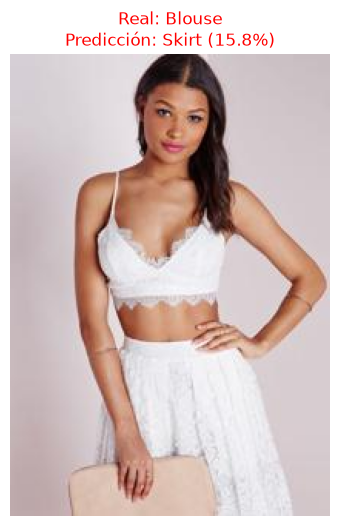


Top 3 predicciones del modelo:
  1. Skirt: 15.78%
  2. Shorts: 14.29%
  3. Dress: 10.02%


In [36]:
import torch
import random
import os
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# 1. Cargar los pesos que acabas de guardar
model.load_state_dict(torch.load('best_convnext_categories.pth', map_location=device))
model.eval()

# 2. Intentar cargar el listado de nombres de categorías reales para el mapeo
category_cloth_file = os.path.join(anno_coarse_folder_path, 'list_category_cloth.txt')
cat_names = {}

if os.path.exists(category_cloth_file):
    try:
        # Este archivo suele tener skiprows=2 y las columnas de nombre de categoría y tipo
        df_names = pd.read_csv(category_cloth_file, sep=r'\s+', skiprows=2, header=None, names=['category_name', 'category_type'])
        # Las categorías van del índice 0 a N-1
        for idx, row in df_names.iterrows():
            cat_names[idx] = row['category_name']
    except Exception as e:
        print(f"No se pudo parsear list_category_cloth.txt: {e}")

# Si no pudimos cargar los nombres, usamos el índice como fallback numérico
if not cat_names:
    cat_names = {i: f"Categoría {i+1}" for i in range(50)}

# 3. Elegir una imagen al azar del conjunto de validación de prueba
idx_aleatorio = random.randint(0, len(df_val_mini) - 1)
row_prueba = df_val_mini.iloc[idx_aleatorio]

# Cargar la imagen
img_path = os.path.join(extract_path, row_prueba['image_name'])
img_pil = Image.open(img_path).convert("RGB")

# Preprocesar para el modelo (usando la transformación de validación)
img_tensor = transform_val(img_pil).unsqueeze(0).to(device)

# 4. Inferencia
with torch.no_grad():
    outputs = model(img_tensor)
    probs = torch.softmax(outputs, dim=1)
    top_probs, top_indices = torch.topk(probs, k=3) # Cogemos el Top 3

# 5. Visualizar la imagen y los resultados
plt.figure(figsize=(6, 6))
plt.imshow(img_pil)
plt.axis('off')

categoria_real = cat_names.get(int(row_prueba['category_label']) - 1, "Desconocida")
pred_top1 = cat_names.get(top_indices[0][0].item(), "Desconocida")
prob_top1 = top_probs[0][0].item() * 100

plt.title(f"Real: {categoria_real}\nPredicción: {pred_top1} ({prob_top1:.1f}%)",
          color=('green' if pred_top1 == categoria_real else 'red'), fontsize=12)
plt.show()

print("\nTop 3 predicciones del modelo:")
for i in range(3):
    idx = top_indices[0][i].item()
    p = top_probs[0][i].item() * 100
    print(f"  {i+1}. {cat_names.get(idx, 'Desconocido')}: {p:.2f}%")